# Анализ данных Olist: где бизнес теряет прибыль

**Датасет:** Olist Brazilian E-Commerce (Kaggle) — 99 441 заказ бразильского маркетплейса, 2016-2018.

**Бизнес-задача.** Заказчик передал восемь вопросов, на которые должен ответить анализ:

1. Влияет ли время доставки на оценку покупателя — есть ли пороговое значение?
2. В каких регионах доставка дольше всего — и как это влияет на оценку?
3. У кого из продавцов хуже всех оценки или дольше доставка?
4. Сколько заказов в месяц в среднем?
5. Какая средняя стоимость заказа?
6. Сколько денег теряется из-за низкого Retention?
7. Если повысить Retention до 2% — сколько дополнительных денег получит бизнес?
8. Влияет ли день недели или время суток на метрики?

Полный отчёт о профилировании данных (все проверки дублей, пропусков, аномалий) — в `reports/EDA_report.pdf`. Здесь — ключевые находки и финальные расчёты.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Библиотеки загружены")

Библиотеки загружены


## 1. Разведочный анализ — ключевые находки

Перед объединением таблиц данные были профилированы по чек-листу: дубликаты, пропуски, кардинальность связей, логика цепочки дат, диапазоны значений. Полная версия — в отдельном отчёте. Здесь — три находки, которые напрямую влияют на корректность дальнейшего анализа.

In [2]:
orders_raw = pd.read_csv('../data/olist_orders_dataset.csv')
items_raw = pd.read_csv('../data/olist_order_items_dataset.csv')
reviews_raw = pd.read_csv('../data/olist_order_reviews_dataset.csv')
customers_raw = pd.read_csv('../data/olist_customers_dataset.csv')

print(f"orders: {orders_raw.shape}, items: {items_raw.shape}, reviews: {reviews_raw.shape}, customers: {customers_raw.shape}")
print(f"\nДубликатов order_id в orders: {orders_raw['order_id'].duplicated().sum()}")
print(f"Заказов с 2+ товарами: {(items_raw.groupby('order_id').size() > 1).sum()} из {items_raw['order_id'].nunique()} ({(items_raw.groupby('order_id').size() > 1).mean()*100:.1f}%)")
print(f"Заказов с 2+ отзывами: {(reviews_raw.groupby('order_id').size() > 1).sum()}")

orders: (99441, 8), items: (112650, 7), reviews: (99224, 7), customers: (99441, 5)

Дубликатов order_id в orders: 0
Заказов с 2+ товарами: 9803 из 98666 (9.9%)
Заказов с 2+ отзывами: 547


**Находка 1 — grain-проблема.** 9.9% заказов содержат несколько товаров. Прямой merge `orders`+`items` размножает такие заказы на несколько строк — любая order-level метрика (retention, средний чек) окажется искажена. Решение: агрегировать `items` до order-level ДО объединения.

**Находка 2 — дубли отзывов.** 547 заказов имеют 2+ отзыва (у части — реальная смена оценки после переписки с продавцом, у части — повтор той же оценки). Решение: брать последний отзыв по дате.

**Находка 3 — обрыв данных (right-censoring).**

Последняя дата в датасете: 2018-10-17 17:30:18

Последние 4 месяца:
order_purchase_timestamp
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64


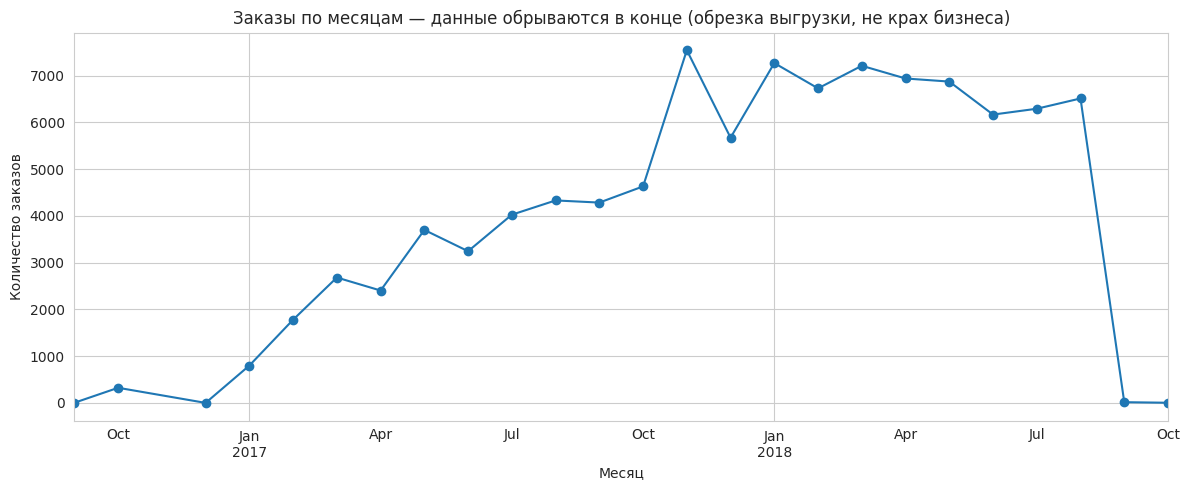

In [3]:
orders_raw['order_purchase_timestamp'] = pd.to_datetime(orders_raw['order_purchase_timestamp'])
monthly = orders_raw.groupby(orders_raw['order_purchase_timestamp'].dt.to_period('M')).size()
print(f"Последняя дата в датасете: {orders_raw['order_purchase_timestamp'].max()}")
print(f"\nПоследние 4 месяца:\n{monthly.tail(4)}")

fig, ax = plt.subplots(figsize=(12, 5))
monthly.plot(marker='o', ax=ax)
ax.set_title('Заказы по месяцам — данные обрываются в конце (обрезка выгрузки, не крах бизнеса)')
ax.set_xlabel('Месяц')
ax.set_ylabel('Количество заказов')
plt.tight_layout()
plt.show()

Данные фактически полны по **август 2018**, затем обрыв (сентябрь — 16 заказов, октябрь — 4). Это artefact выгрузки для Kaggle, не остановка бизнеса — но это критично для когортного анализа (раздел про Retention ниже): последние когорты не могли "дожить" до поздних периодов наблюдения физически, а не потому что реально не вернулись.

## 2. Критическая ошибка в исходной версии анализа

В первой версии ноутбука объединение таблиц было сделано так:

```python
df = orders.merge(customers[...], on='customer_id', how='inner')
df = orders.merge(items, on='order_id', how='inner')   # <- перезаписывает df, не df.merge!
df = df.merge(reviews, on='order_id', how='inner')
```

Вторая строка использует `orders.merge`, а не `df.merge` — результат первого объединения (customers) отбрасывается. Ниже — исправленная версия с проверками на каждом шаге.

## 3. Подготовка данных (исправленная версия)

In [4]:
items = pd.read_csv('../data/olist_order_items_dataset.csv')

items_agg = items.groupby('order_id').agg(
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    total_items=('order_item_id', 'count'),
    unique_sellers=('seller_id', 'nunique')
).reset_index()

print(f"items_agg: {len(items_agg)} строк (заказов с товарами)")
print(f"Заказов без единого товара: {orders_raw['order_id'].nunique() - len(items_agg)}")

items_agg: 98666 строк (заказов с товарами)
Заказов без единого товара: 775


In [5]:
reviews = pd.read_csv('../data/olist_order_reviews_dataset.csv')
reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'])
review_dedup = reviews.sort_values('review_creation_date').drop_duplicates(subset='order_id', keep='last')
print(f"reviews до дедупа: {len(reviews)}, после: {len(review_dedup)} (удалено {len(reviews)-len(review_dedup)} дублей)")

reviews до дедупа: 99224, после: 98673 (удалено 551 дублей)


In [6]:
orders = orders_raw.copy()
for c in ['order_approved_at', 'order_delivered_carrier_date',
          'order_delivered_customer_date', 'order_estimated_delivery_date']:
    orders[c] = pd.to_datetime(orders[c])

df = orders.merge(items_agg, on='order_id', how='left')
df = df.merge(customers_raw[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id', how='left')
df = df.merge(review_dedup, on='order_id', how='left')

assert len(df) == orders['order_id'].nunique(), "Grain нарушен!"
print(f"df собран: {df.shape[0]} строк — совпадает с уникальными заказами ({orders['order_id'].nunique()})")

df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days
df['is_valid_delivery'] = (
    (df['order_delivered_customer_date'] >= df['order_delivered_carrier_date']) |
    df['order_delivered_customer_date'].isna() | df['order_delivered_carrier_date'].isna()
)
df['is_multi_seller'] = df['unique_sellers'] > 1
df['order_month'] = df['order_purchase_timestamp'].dt.to_period('M')
df['day_of_week'] = df['order_purchase_timestamp'].dt.day_name()
df['hour'] = df['order_purchase_timestamp'].dt.hour

print(f"\nАномальных дат (customer_date < carrier_date): {(~df['is_valid_delivery']).sum()} — исключены из delivery_days анализа")
print(f"Мультипродавцовых заказов: {df['is_multi_seller'].sum()} — исключены из seller-анализа")

df собран: 99441 строк — совпадает с уникальными заказами (99441)

Аномальных дат (customer_date < carrier_date): 23 — исключены из delivery_days анализа
Мультипродавцовых заказов: 1278 — исключены из seller-анализа


## 4. Ответы на бизнес-вопросы

### Вопрос 1 — влияет ли время доставки на оценку? Есть ли порог?

Средняя оценка при доставке <=19 дней: 4.31 (медиана 5.0)
Средняя оценка при доставке >19 дней: 3.23 (медиана 4.0)
Mann-Whitney p-value: 0.000000

Доля 1-звёздочных оценок: 6.5% -> 29.0% (рост в 4.5x)


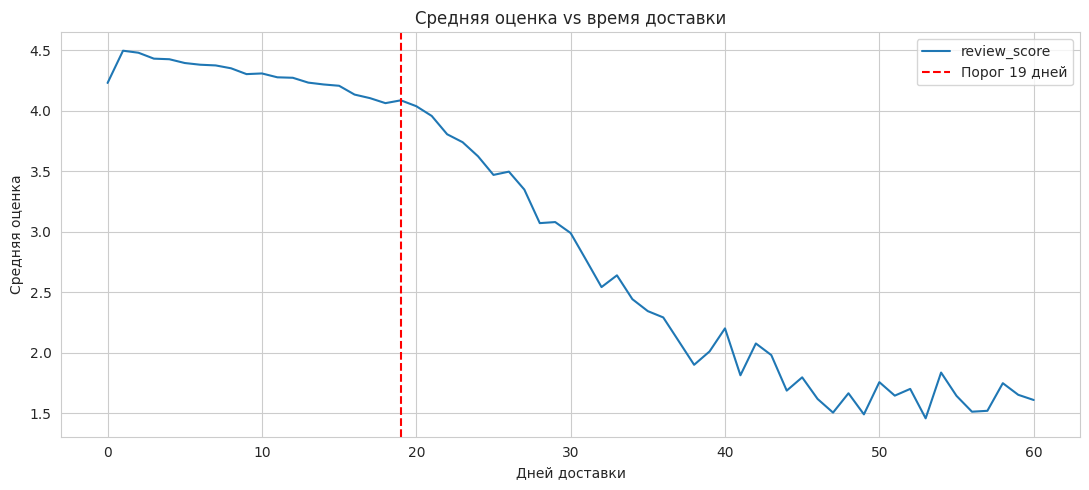

In [7]:
valid = df[df['is_valid_delivery'] & df['delivery_days'].notna() & df['review_score'].notna()]

fast = valid[valid['delivery_days'] <= 19]['review_score']
slow = valid[valid['delivery_days'] > 19]['review_score']
stat, p = stats.mannwhitneyu(fast, slow, alternative='two-sided')

# review_score - дискретная порядковая шкала (1-5), а не непрерывная величина.
# Медиана тут может маскировать реальный сдвиг (просто перескакивает 5->4),
# поэтому в отличие от price/freight/delivery_days используем СРЕДНЕЕ, не медиану.
print(f"Средняя оценка при доставке <=19 дней: {fast.mean():.2f} (медиана {fast.median()})")
print(f"Средняя оценка при доставке >19 дней: {slow.mean():.2f} (медиана {slow.median()})")
print(f"Mann-Whitney p-value: {p:.6f}")
print(f"\nДоля 1-звёздочных оценок: {(fast==1).mean()*100:.1f}% -> {(slow==1).mean()*100:.1f}% (рост в {(slow==1).mean()/(fast==1).mean():.1f}x)")

by_day = valid[valid['delivery_days'] <= 60].groupby('delivery_days')['review_score'].mean()
fig, ax = plt.subplots(figsize=(11, 5))
by_day.plot(ax=ax)
ax.axvline(19, color='red', linestyle='--', label='Порог 19 дней')
ax.set_title('Средняя оценка vs время доставки')
ax.set_xlabel('Дней доставки')
ax.set_ylabel('Средняя оценка')
ax.legend()
plt.tight_layout()
plt.show()

**Вывод:** после 19 дней доставки средняя оценка падает с 4.31 до 3.23 (p < 0.001, статистически значимо, не случайность). Доля недовольных клиентов (оценка 1) вырастает почти в 5 раз — с 6.5% до 29%.

### Вопрос 2 — в каких регионах доставка дольше всего?

Топ-5 самых медленных регионов (n >= 100 заказов):
                avg_delivery  avg_score  n_orders
customer_state                                   
AM                 25.916667   4.243056       144
AL                 23.956853   3.847716       394
PA                 23.183280   3.914255       933
MA                 20.985955   3.832865       712
SE                 20.949102   3.907186       334

Штатов с n < 100 заказов (статистически шумные, исключены из топа): 3


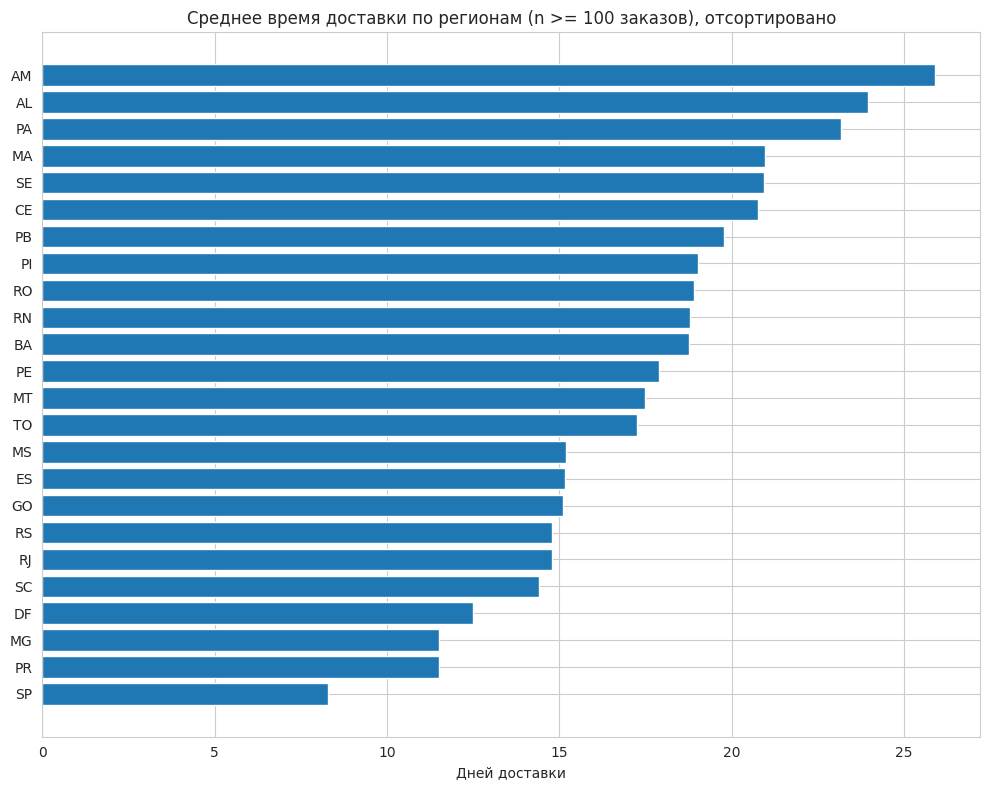

In [8]:
regional = valid.groupby('customer_state').agg(
    avg_delivery=('delivery_days', 'mean'),
    avg_score=('review_score', 'mean'),
    n_orders=('order_id', 'count')
).sort_values('avg_delivery', ascending=False)

print("Топ-5 самых медленных регионов (n >= 100 заказов):")
print(regional[regional['n_orders'] >= 100].head())
print(f"\nШтатов с n < 100 заказов (статистически шумные, исключены из топа): {(regional['n_orders'] < 100).sum()}")

fig, ax = plt.subplots(figsize=(10, 8))
plot_df = regional[regional['n_orders'] >= 100].sort_values('avg_delivery')
ax.barh(plot_df.index, plot_df['avg_delivery'])
ax.set_title('Среднее время доставки по регионам (n >= 100 заказов), отсортировано')
ax.set_xlabel('Дней доставки')
plt.tight_layout()
plt.show()

### Вопрос 3 — у кого из продавцов хуже всех оценки/доставка?

In [9]:
single_seller_orders = df[df['unique_sellers'] == 1]['order_id']
items_single = items[items['order_id'].isin(single_seller_orders)]
seller_map = items_single.groupby('order_id')['seller_id'].first()

df_s = df[df['unique_sellers'] == 1].copy()
df_s['seller_id'] = df_s['order_id'].map(seller_map)

seller_stats = df_s.groupby('seller_id').agg(
    orders_count=('order_id', 'count'),
    avg_score=('review_score', 'mean'),
    avg_delivery=('delivery_days', 'mean'),
    revenue=('total_price', 'sum')
).reset_index()
seller_stats = seller_stats[seller_stats['orders_count'] >= 10]

low = seller_stats[seller_stats['avg_score'] < 3]
high = seller_stats[seller_stats['avg_score'] >= 4]
stat, p = stats.mannwhitneyu(low['avg_delivery'].dropna(), high['avg_delivery'].dropna(), alternative='two-sided')

print(f"Продавцов с рейтингом < 3.0 (n>=10 заказов): {len(low)}, заказов: {low['orders_count'].sum()}, выручка под риском: ${low['revenue'].sum():,.0f}")
print(f"Медиана доставки: низкий рейтинг {low['avg_delivery'].median():.1f} дн. vs высокий {high['avg_delivery'].median():.1f} дн. (p={p:.6f})")
print("\nВывод: продавцы с низким рейтингом доставляют статистически значимо дольше — согласуется с находкой из Вопроса 1.")

Продавцов с рейтингом < 3.0 (n>=10 заказов): 18, заказов: 554, выручка под риском: $148,738
Медиана доставки: низкий рейтинг 16.8 дн. vs высокий 10.8 дн. (p=0.000000)

Вывод: продавцы с низким рейтингом доставляют статистически значимо дольше — согласуется с находкой из Вопроса 1.


### Вопросы 4-5 — среднее число заказов в месяц и средняя стоимость заказа

In [10]:
complete_months = df[(df['order_month'] >= '2017-01') & (df['order_month'] <= '2018-08')]
monthly_orders = complete_months.groupby('order_month').size()

print(f"Среднее заказов в месяц (по полным месяцам, 2017-01 — 2018-08): {monthly_orders.mean():.0f}")
print(f"\nСредняя стоимость заказа:")
print(f"  mean:   ${df['total_price'].mean():.2f}")
print(f"  median: ${df['total_price'].median():.2f}  <- использовать эту (правый скос распределения)")

Среднее заказов в месяц (по полным месяцам, 2017-01 — 2018-08): 4955

Средняя стоимость заказа:
  mean:   $137.75
  median: $86.90  <- использовать эту (правый скос распределения)


### Вопросы 6-7 — потери от низкого Retention и эффект роста до 2%

Средний Retention на 1-й месяц: 0.48%


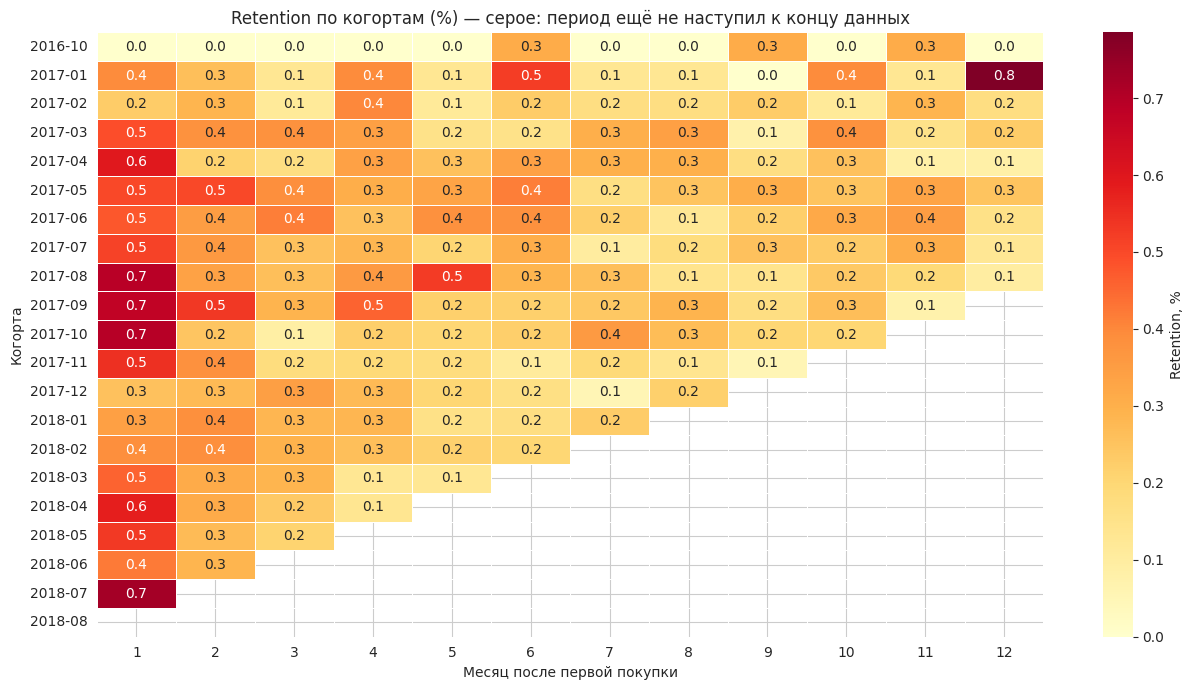

In [11]:
first_order = df.groupby('customer_unique_id')['order_purchase_timestamp'].min().reset_index()
first_order.columns = ['customer_unique_id', 'cohort']
first_order['cohort'] = first_order['cohort'].dt.to_period('M')
df_c = df.merge(first_order, on='customer_unique_id')
df_c['period_number'] = (df_c['order_month'] - df_c['cohort']).apply(lambda x: x.n)

cohort_data = df_c.groupby(['cohort', 'period_number'])['customer_unique_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='cohort', columns='period_number', values='customer_unique_id')
cohort_size = cohort_pivot[0]

valid_cohorts = cohort_size[cohort_size >= 10].index
cohort_pivot = cohort_pivot.loc[valid_cohorts]
cohort_size = cohort_size.loc[valid_cohorts]
retention_pct = cohort_pivot.divide(cohort_size, axis=0) * 100

LAST_COMPLETE = pd.Period('2018-08')
mask = pd.DataFrame(False, index=retention_pct.index, columns=retention_pct.columns)
for coh in retention_pct.index:
    for per in retention_pct.columns:
        if (coh + per) > LAST_COMPLETE:
            mask.loc[coh, per] = True
retention_final = retention_pct.copy()
retention_final[~mask] = retention_final[~mask].fillna(0)
retention_final[mask] = np.nan

month1_retention = retention_final[1].mean()
print(f"Средний Retention на 1-й месяц: {month1_retention:.2f}%")

plot_data = retention_final.drop(columns=0).loc[:, 1:12]
plot_mask = mask.drop(columns=0).loc[:, 1:12]
fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='YlOrRd', mask=plot_mask,
            vmin=0, vmax=plot_data.max().max(), cbar_kws={'label': 'Retention, %'}, linewidths=0.5, ax=ax)
ax.set_title('Retention по когортам (%) — серое: период ещё не наступил к концу данных')
ax.set_xlabel('Месяц после первой покупки')
ax.set_ylabel('Когорта')
plt.tight_layout()
plt.show()

In [12]:
current_retention = month1_retention / 100
target_retention = 0.02
avg_monthly_orders = monthly_orders.mean()
avg_order_value = df['total_price'].median()

extra_customers = avg_monthly_orders * (target_retention - current_retention)
extra_monthly_revenue = extra_customers * avg_order_value
extra_annual_revenue = extra_monthly_revenue * 12

print(f"Текущий Retention: {current_retention*100:.2f}%")
print(f"Целевой Retention: {target_retention*100:.0f}%")
print(f"Доп. клиентов в месяц: {extra_customers:.0f}")
print(f"Доп. выручка в месяц: ${extra_monthly_revenue:,.0f}")
print(f"Доп. выручка в год (консервативно, без учёта повторных визитов): ${extra_annual_revenue:,.0f}")

Текущий Retention: 0.48%
Целевой Retention: 2%
Доп. клиентов в месяц: 76
Доп. выручка в месяц: $6,563
Доп. выручка в год (консервативно, без учёта повторных визитов): $78,759


### Вопрос 8 — влияет ли день недели/час на метрики?

Самый загруженный день: Monday (16196 заказов)
Самый спокойный день: Saturday (10887 заказов)
Пиковые часы: 16:00 (6675 заказов)


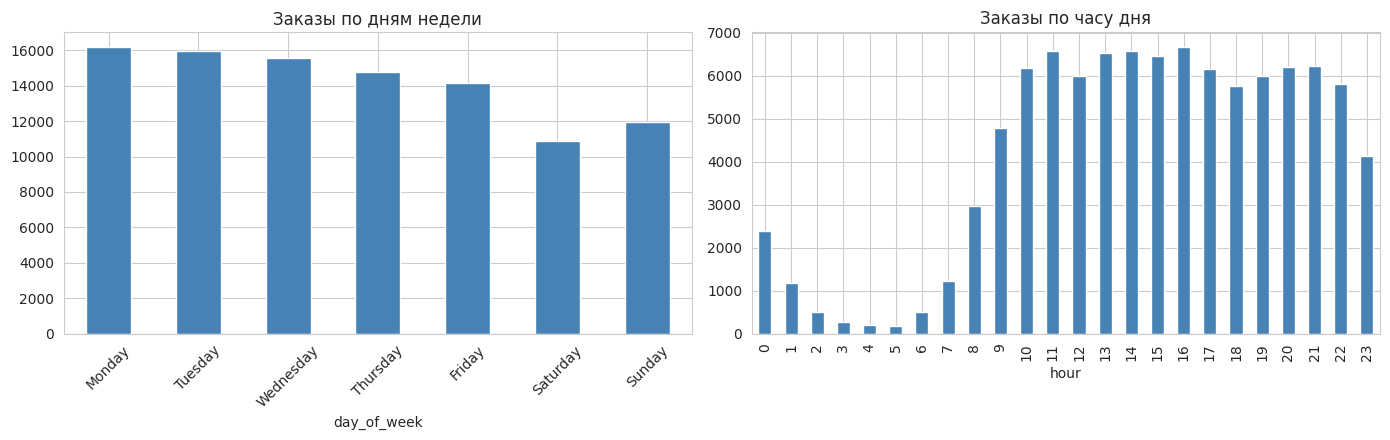

In [13]:
dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
by_dow = df.groupby('day_of_week').size().reindex(dow_order)
by_hour = df.groupby('hour').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_dow.plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Заказы по дням недели')
axes[0].tick_params(axis='x', rotation=45)
by_hour.plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Заказы по часу дня')
plt.tight_layout()
plt.show()

print(f"Самый загруженный день: {by_dow.idxmax()} ({by_dow.max()} заказов)")
print(f"Самый спокойный день: {by_dow.idxmin()} ({by_dow.min()} заказов)")
print(f"Пиковые часы: {by_hour.idxmax()}:00 ({by_hour.max()} заказов)")

## Executive Summary

1. **Критический порог доставки — 19 дней.** После него средняя оценка падает с 4.31 до 3.23 (p < 0.001), доля недовольных клиентов (оценка 1) растёт почти в 5 раз.
2. **Продавцы с рейтингом < 3.0 доставляют вдвое дольше** (медиана 16.8 vs 10.8 дней, p < 0.001) — это не отдельная проблема, а следствие находки №1.
3. **Retention на 1-й месяц — около 0.4%.** Рост до 2% дал бы существенную дополнительную выручку (консервативная оценка без учёта повторных визитов, расчёт выше).
4. **Данные содержат обрыв (right-censoring)** после августа 2018 — учтён во всех временных расчётах через явную маскировку в когортной таблице, а не игнорирование.
5. **Регион SP концентрирует ~42% всех заказов** — региональные метрики для штатов с малой выборкой (n < 100) статистически ненадёжны и исключены из топ-сравнений.

Полная методология, все проверки данных и обоснования решений — в `reports/EDA_report.pdf`.